# Lab Sheet 4 – Fine-Tuning an LLM using LoRA

**Module:** PUSL 3205 – Large Language Models and Generative AI  
**Practical domain:** Computer-shop question answering

## Objective
Fine-tune a small instruction-tuned causal language model using PEFT LoRA, then compare the base and fine-tuned models using the same unseen questions.

**Important compatibility decision:** This notebook uses FP16 on CUDA GPUs and deliberately disables BF16. This avoids the BF16 matrix-operation error encountered on GPUs such as the Tesla T4 (compute capability 7.5). It uses Hugges Face `Trainer` with PEFT LoRA rather than TRL's chunked-log-probability path, which was the source of the reported error. This is still supervised fine-tuning (SFT).

## Step 1 – Install the required libraries

Run this cell once. If the runtime requests a restart, restart it and continue from Step 2. The code below avoids upgrading PyTorch in the middle of a Colab session.

In [1]:
%pip install -q -U transformers datasets peft accelerate bitsandbytes sentencepiece pandas matplotlib openpyxl

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## Step 2 – Check the hardware and GPU

A GPU accelerates the matrix operations used in neural-network training. The notebook automatically uses FP16 on CUDA and FP32 on CPU. BF16 is intentionally disabled for compatibility.

In [2]:
import os, gc, json, random, zipfile, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling,
)
from peft import LoraConfig, get_peft_model, PeftModel

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 60)
print("HARDWARE INFORMATION")
print("=" * 60)
print("Python / PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name)
    print(f"GPU memory: {props.total_memory / 1024**3:.2f} GB")
    print("Compute capability:", torch.cuda.get_device_capability(0))
    print("CUDA version:", torch.version.cuda)
    print("Training precision: FP16 (BF16 disabled)")
    DEVICE = "cuda"
    MODEL_DTYPE = torch.float16
else:
    print("No CUDA GPU detected. CPU training will be significantly slower.")
    DEVICE = "cpu"
    MODEL_DTYPE = torch.float32

print("=" * 60)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


HARDWARE INFORMATION
Python / PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB
Compute capability: (7, 5)
CUDA version: 13.0
Training precision: FP16 (BF16 disabled)


## Step 3 – Configure the model and output folders

The selected model is `Qwen/Qwen2.5-0.5B-Instruct`. The base model is small enough for a practical LoRA demonstration.

In [3]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

# Colab paths; change BASE_DIR if running outside Google Colab.
BASE_DIR = "/content" if os.path.exists("/content") else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "lab4_lora_computer_shop")
ADAPTER_DIR = os.path.join(OUTPUT_DIR, "adapter")
RESULT_DIR = os.path.join(BASE_DIR, "Lab4_Results")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(ADAPTER_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

MAX_LENGTH = 512
SYSTEM_PROMPT = (
    "You are a helpful computer shop assistant. Answer clearly, accurately "
    "and concisely about computers, computer hardware and accessories. "
    "If you are unsure, say so."
)

print("Model:", MODEL_NAME)
print("Output directory:", OUTPUT_DIR)
print("Results directory:", RESULT_DIR)

Model: Qwen/Qwen2.5-0.5B-Instruct
Output directory: /content/lab4_lora_computer_shop
Results directory: /content/Lab4_Results


## Step 4 – Create the computer-shop Q&A dataset

The dataset contains at least 30 question-and-answer examples, as required by the practical.

In [4]:
# STEP 4: CREATE THE REQUIRED COMPUTER-SHOP QUESTION-ANSWER DATASET

training_data = [

    {
        "question": "What products does your computer shop sell?",
        "answer": "Our computer shop sells laptops, desktop computers, processors, RAM, graphics cards, SSDs, hard drives, keyboards, mice, monitors and other computer accessories."
    },

    {
        "question": "What is a processor?",
        "answer": "A processor, also called a CPU, is the main component that executes instructions and performs calculations in a computer."
    },

    {
        "question": "What is RAM?",
        "answer": "RAM stands for Random Access Memory. It temporarily stores data that the computer is actively using. More RAM helps a computer handle multiple applications."
    },

    {
        "question": "What is an SSD?",
        "answer": "An SSD is a Solid State Drive used for permanent data storage. It is generally faster than a traditional hard disk drive."
    },

    {
        "question": "What is an HDD?",
        "answer": "An HDD is a Hard Disk Drive that stores data using rotating magnetic disks. It is commonly used for storing files and applications."
    },

    {
        "question": "What is a graphics card?",
        "answer": "A graphics card or GPU processes graphical information. It is useful for gaming, video editing, 3D rendering and machine learning."
    },

    {
        "question": "Which is better, SSD or HDD?",
        "answer": "An SSD is generally better for speed and system performance, while an HDD is often more economical for storing large amounts of data."
    },

    {
        "question": "What is the difference between Intel and AMD processors?",
        "answer": "Intel and AMD are processor manufacturers. Both offer CPUs for everyday computing, gaming and professional workloads. Performance depends on the specific processor model."
    },

    {
        "question": "How much RAM is suitable for gaming?",
        "answer": "16GB of RAM is a common starting point for modern gaming. 32GB can provide additional capacity for demanding games and multitasking."
    },

    {
        "question": "What is a motherboard?",
        "answer": "A motherboard is the main circuit board that connects the processor, RAM, storage devices, graphics card and other computer components."
    },

    {
        "question": "What is a power supply unit?",
        "answer": "A power supply unit, or PSU, converts electricity from the wall outlet into the power required by computer components."
    },

    {
        "question": "What is a computer monitor?",
        "answer": "A monitor is an output device that displays images, videos, text and other visual information generated by a computer."
    },

    {
        "question": "What is a mechanical keyboard?",
        "answer": "A mechanical keyboard uses individual mechanical switches beneath its keys. It often provides tactile feedback and can be preferred for typing and gaming."
    },

    {
        "question": "What is a gaming mouse?",
        "answer": "A gaming mouse is designed for computer gaming and commonly offers adjustable sensitivity, additional buttons and precise tracking."
    },

    {
        "question": "What is a laptop?",
        "answer": "A laptop is a portable computer that combines a display, keyboard, touchpad, battery and internal computer components in one device."
    },

    {
        "question": "What is the difference between a laptop and a desktop?",
        "answer": "A laptop is portable and has built-in components, while a desktop generally uses separate components and offers greater flexibility for upgrades."
    },

    {
        "question": "What does CPU generation mean?",
        "answer": "CPU generation identifies a processor's product generation. Newer generations may offer architectural improvements, but actual performance depends on the model."
    },

    {
        "question": "What is a GPU?",
        "answer": "A GPU is a Graphics Processing Unit. It handles parallel processing tasks, particularly graphics rendering and other highly parallel workloads."
    },

    {
        "question": "What is thermal paste?",
        "answer": "Thermal paste is a heat-conductive material placed between a processor and its cooler to improve heat transfer."
    },

    {
        "question": "Why does a computer overheat?",
        "answer": "A computer may overheat because of dust buildup, poor airflow, insufficient cooling, high workloads or a malfunctioning cooling system."
    },

    {
        "question": "What should I do if my computer is slow?",
        "answer": "Check available storage, startup applications, background processes and RAM usage. Upgrading to an SSD or adding RAM may also improve performance."
    },

    {
        "question": "Why is my laptop battery draining quickly?",
        "answer": "Battery drain can be caused by high screen brightness, background applications, heavy workloads, battery aging or incorrect power settings."
    },

    {
        "question": "What is a USB flash drive?",
        "answer": "A USB flash drive is a portable storage device used to save and transfer files between compatible devices."
    },

    {
        "question": "What is a Wi-Fi adapter?",
        "answer": "A Wi-Fi adapter allows a computer to connect to wireless networks and access the internet."
    },

    {
        "question": "What is Bluetooth?",
        "answer": "Bluetooth is a wireless communication technology used to connect nearby devices such as headphones, keyboards, mice and speakers."
    },

    {
        "question": "What is an operating system?",
        "answer": "An operating system is system software that manages computer hardware and software resources. Examples include Windows, Linux and macOS."
    },

    {
        "question": "Can I upgrade my laptop RAM?",
        "answer": "Some laptops support RAM upgrades, while others have soldered memory. Check the laptop's specifications and maximum supported memory before purchasing RAM."
    },

    {
        "question": "Can I install an SSD in my desktop?",
        "answer": "Yes. Most desktop computers support SSD installation through compatible SATA or M.2 connections. Check motherboard compatibility before purchasing."
    },

    {
        "question": "What is an HDMI cable used for?",
        "answer": "An HDMI cable transmits digital video and audio signals between compatible devices such as computers, monitors and televisions."
    },

    {
        "question": "What is a refresh rate?",
        "answer": "Refresh rate is the number of times a display updates its image per second, measured in Hertz. For example, 144Hz means 144 updates per second."
    },

    {
        "question": "What is screen resolution?",
        "answer": "Screen resolution describes the number of pixels displayed on a screen. A common Full HD resolution is 1920 by 1080 pixels."
    },

    {
        "question": "What is a gaming laptop?",
        "answer": "A gaming laptop is a laptop designed for gaming, usually featuring a powerful processor, dedicated graphics and an advanced cooling system."
    },

    {
        "question": "What is a computer case?",
        "answer": "A computer case houses and protects desktop components such as the motherboard, power supply, storage devices and cooling fans."
    },

    {
        "question": "Why do computers need cooling fans?",
        "answer": "Cooling fans move air through the computer to remove heat from components and maintain safe operating temperatures."
    },

    {
        "question": "What is a network cable?",
        "answer": "A network cable, commonly an Ethernet cable, connects devices to a wired network or router for network and internet access."
    },

    {
        "question": "What is a webcam?",
        "answer": "A webcam is a camera that connects to a computer and is commonly used for video calls, online meetings and recording."
    },

    {
        "question": "Do you sell computer accessories?",
        "answer": "Yes. Our computer shop offers accessories such as keyboards, mice, mouse pads, headphones, webcams, USB drives and cables."
    },

    {
        "question": "How can I choose a laptop for university?",
        "answer": "Consider the processor, RAM, SSD capacity, battery life, portability and software requirements of your degree. For programming and data analysis, 16GB RAM is a useful starting point."
    },

    {
        "question": "What should I check before buying a graphics card?",
        "answer": "Check its performance, VRAM capacity, power consumption, physical dimensions, power connector requirements and compatibility with your motherboard and PSU."
    },

    {
        "question": "How can I contact the computer shop?",
        "answer": "You can contact the computer shop through its official phone number, email address or website. Please check the shop's official contact information for current details."
    }

]

print("Total training examples:", len(training_data))

assert len(training_data) >= 30

print("\nFirst 3 examples:")

for item in training_data[:3]:
    print("\nQuestion:", item["question"])
    print("Answer:", item["answer"])

Total training examples: 40

First 3 examples:

Question: What products does your computer shop sell?
Answer: Our computer shop sells laptops, desktop computers, processors, RAM, graphics cards, SSDs, hard drives, keyboards, mice, monitors and other computer accessories.

Question: What is a processor?
Answer: A processor, also called a CPU, is the main component that executes instructions and performs calculations in a computer.

Question: What is RAM?
Answer: RAM stands for Random Access Memory. It temporarily stores data that the computer is actively using. More RAM helps a computer handle multiple applications.


## Step 5 – Prepare the dataset for supervised fine-tuning

Each example is formatted as a chat conversation. We tokenize the prompt and answer together, and mask the prompt tokens with `-100` so the training loss is calculated on the assistant answer rather than on the system/user prompt.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

def build_training_record(item):
    prompt_messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": item["question"]},
    ]
    full_messages = prompt_messages + [
        {"role": "assistant", "content": item["answer"]}
    ]

    prompt_text = tokenizer.apply_chat_template(
        prompt_messages, tokenize=False, add_generation_prompt=True
    )
    full_text = tokenizer.apply_chat_template(
        full_messages, tokenize=False, add_generation_prompt=False
    )

    prompt_ids = tokenizer(
        prompt_text, add_special_tokens=False, truncation=True,
        max_length=MAX_LENGTH
    )["input_ids"]
    full_ids = tokenizer(
        full_text, add_special_tokens=False, truncation=True,
        max_length=MAX_LENGTH
    )["input_ids"]

    labels = list(full_ids)
    prompt_length = min(len(prompt_ids), len(labels))
    labels[:prompt_length] = [-100] * prompt_length

    # Ensure at least one answer token contributes to loss.
    if all(x == -100 for x in labels):
        labels[-1] = full_ids[-1]

    return {"input_ids": full_ids, "attention_mask": [1] * len(full_ids), "labels": labels}

records = [build_training_record(item) for item in training_data]
train_dataset = Dataset.from_list(records)

print("Training records:", len(train_dataset))
print("Dataset columns:", train_dataset.column_names)
print("Example token length:", len(train_dataset[0]["input_ids"]))
assert len(training_data) >= 30
assert len(train_dataset) == len(training_data)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Training records: 40
Dataset columns: ['input_ids', 'attention_mask', 'labels']
Example token length: 87


## Step 6 – Define unseen evaluation questions

These questions are not copied from the training questions. The exact same test set will be used for the base and fine-tuned models.

In [6]:
test_questions = [
    "My computer turns on but shows a black screen. What should I check?",
    "Which storage device should I choose for faster boot times?",
    "Can I use a 650W power supply with a gaming computer?",
    "What is the purpose of a CPU cooler?",
    "Why should I check motherboard compatibility before buying RAM?",
    "What is the benefit of a 144Hz gaming monitor?",
    "Which specifications are important for a computer used for video editing?",
    "My computer disconnects from Wi-Fi frequently. What should I do?"
]

training_questions = {x["question"].strip().lower() for x in training_data}
assert not any(q.strip().lower() in training_questions for q in test_questions)
print("Unseen test questions:", len(test_questions))
for n, q in enumerate(test_questions, 1):
    print(f"{n}. {q}")

Unseen test questions: 8
1. My computer turns on but shows a black screen. What should I check?
2. Which storage device should I choose for faster boot times?
3. Can I use a 650W power supply with a gaming computer?
4. What is the purpose of a CPU cooler?
5. Why should I check motherboard compatibility before buying RAM?
6. What is the benefit of a 144Hz gaming monitor?
7. Which specifications are important for a computer used for video editing?
8. My computer disconnects from Wi-Fi frequently. What should I do?


## Step 7 – Load and evaluate the original model

The base model's answers are saved before fine-tuning so they can be compared fairly with the fine-tuned model.

In [7]:
def load_base_model():
    kwargs = {"torch_dtype": MODEL_DTYPE}
    if torch.cuda.is_available():
        kwargs["device_map"] = "auto"
    else:
        kwargs["device_map"] = "cpu"
    return AutoModelForCausalLM.from_pretrained(MODEL_NAME, **kwargs)

def generate_answer(model, question, max_new_tokens=120):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt")
    model_device = model.get_input_embeddings().weight.device
    inputs = {k: v.to(model_device) for k, v in inputs.items()}

    model.eval()
    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    answer_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(answer_tokens, skip_special_tokens=True).strip()

base_model = load_base_model()
base_model.config.pad_token_id = tokenizer.pad_token_id
baseline_results = []

for idx, question in enumerate(test_questions, 1):
    answer = generate_answer(base_model, question)
    baseline_results.append({"Question": question, "Base Model Answer": answer})
    print(f"\nQ{idx}: {question}\nBASE: {answer}\n" + "-" * 60)

baseline_df = pd.DataFrame(baseline_results)
baseline_df.to_csv(
    os.path.join(RESULT_DIR, "baseline_results.csv"),
    index=False, encoding="utf-8-sig"
)
print("Base-model results saved.")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


Q1: My computer turns on but shows a black screen. What should I check?
BASE: If your computer turns on but displays a black screen, there are several things you can check to troubleshoot the issue:

1. **Check Power Supply**: Ensure that your power supply is functioning properly. Sometimes, a faulty power supply can cause the computer to turn on but not display anything.

2. **Check Hard Drive**: Make sure your hard drive is not damaged or failing. A bad sector or a corrupted file can cause the computer to display a black screen.

3. **Check RAM**: If your computer has RAM, make sure it is not fully charged or if it is running low. RAM
------------------------------------------------------------

Q2: Which storage device should I choose for faster boot times?
BASE: For faster boot times, you should consider using a solid-state drive (SSD) over an external hard drive (HDD). SSDs are faster to read and write data compared to HDDs, which can significantly improve boot times. They also o

## Step 8 – Configure LoRA using PEFT

LoRA trains small low-rank adapter matrices instead of updating all model parameters. This reduces memory use and the number of trainable parameters.

In [8]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
)
print(lora_config)

LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.22.0', base_model_name_or_path=None, revision=None, inference_mode=False, r=8, target_modules={'gate_proj', 'o_proj', 'up_proj', 'v_proj', 'down_proj', 'q_proj', 'k_proj'}, exclude_modules=None, lora_alpha=16, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, astra_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_config=None

## Step 9 – Release the base model and prepare the LoRA model

The baseline answers have been saved. The base model is released to free GPU memory before training. BF16 is not used; the model is loaded in FP16 when CUDA is available.

In [9]:
del base_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free_mem, total_mem = torch.cuda.mem_get_info()
    print(f"Free GPU memory: {free_mem / 1024**3:.2f} GB")
    print(f"Total GPU memory: {total_mem / 1024**3:.2f} GB")

model = load_base_model()
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False

# Gradient checkpointing is deliberately disabled for this small model.
# This avoids unnecessary complexity with input-gradient hooks during this practical.
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

first_param_dtype = next(model.parameters()).dtype
print("Model parameter dtype:", first_param_dtype)
if torch.cuda.is_available():
    assert first_param_dtype == torch.float16, "CUDA model should be FP16."

Free GPU memory: 13.51 GB
Total GPU memory: 14.56 GB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826
Model parameter dtype: torch.float16


## Step 10 – Configure supervised fine-tuning

This notebook uses the standard Hugging Face `Trainer` with PEFT LoRA. It avoids TRL's chunked-log-probability kernel that caused the reported BF16 matrix-operation error. The loss is still supervised on the assistant-answer tokens.

In [10]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=3,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    logging_steps=1,
    save_strategy="epoch",
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    bf16=False,
    optim="adamw_torch",
    report_to="none",
    remove_unused_columns=False,
    dataloader_pin_memory=torch.cuda.is_available(),
    seed=SEED,
)

print("FP16:", training_args.fp16)
print("BF16:", training_args.bf16)
print("Epochs:", training_args.num_train_epochs)
assert training_args.bf16 is False

FP16: True
BF16: False
Epochs: 3


## Step 11 – Initialize the data collator and Trainer

The collator pads sequences within each batch. Padding labels are set to `-100`, so padding does not contribute to the training loss.

In [11]:
class CausalLMCollator:
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer

    def __call__(self, features):
        batch = self.tokenizer.pad(
            [{"input_ids": f["input_ids"], "attention_mask": f["attention_mask"]}
             for f in features],
            padding=True,
            return_tensors="pt",
        )
        max_len = batch["input_ids"].shape[1]
        labels = []
        for f in features:
            row = list(f["labels"])
            row += [-100] * (max_len - len(row))
            labels.append(row)
        batch["labels"] = torch.tensor(labels, dtype=torch.long)
        return batch

data_collator = CausalLMCollator(tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    data_collator=data_collator,
)

print("Trainer initialized.")
print("Training samples:", len(train_dataset))

Trainer initialized.
Training samples: 40


## Step 12 – Train the LoRA adapter

Run this cell to start fine-tuning. On a GPU this should be substantially faster than CPU training. If a CUDA out-of-memory error occurs, reduce `MAX_LENGTH` to 384 or 256 and rerun the notebook from Step 5.

In [12]:
training_result = trainer.train()
print("\nFine-tuning completed.")
print("Training loss:", training_result.training_loss)
print("Training metrics:", training_result.metrics)

Step,Training Loss
1,2.090307
2,1.790412
3,2.046565
4,1.821445
5,1.641784
6,1.662150
7,1.965074
8,1.726463
9,1.964077
10,1.354814



Fine-tuning completed.
Training loss: 1.3604435265064239
Training metrics: {'train_runtime': 46.7078, 'train_samples_per_second': 2.569, 'train_steps_per_second': 0.642, 'total_flos': 20483559998208.0, 'train_loss': 1.3604435265064239, 'epoch': 3.0}


## Step 13 – Save the fine-tuned adapter

The adapter is saved separately from the base model. To use it later, load the original base model and attach this adapter.

In [13]:
os.makedirs(ADAPTER_DIR, exist_ok=True)
trainer.model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print("Adapter saved to:", ADAPTER_DIR)
print("Adapter files:", sorted(os.listdir(ADAPTER_DIR)))
assert any(name in os.listdir(ADAPTER_DIR) for name in ["adapter_config.json", "adapter_model.safetensors", "adapter_model.bin"])

Adapter saved to: /content/lab4_lora_computer_shop/adapter
Adapter files: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json']


## Step 14 – Evaluate the fine-tuned model

Use exactly the same unseen test questions used for the original model.

In [14]:
model.eval()
fine_tuned_results = []

for idx, question in enumerate(test_questions, 1):
    answer = generate_answer(model, question)
    fine_tuned_results.append({
        "Question": question,
        "Fine-Tuned Model Answer": answer,
    })
    print(f"\nQ{idx}: {question}\nFINE-TUNED: {answer}\n" + "-" * 60)

fine_tuned_df = pd.DataFrame(fine_tuned_results)
fine_tuned_df.to_csv(
    os.path.join(RESULT_DIR, "fine_tuned_results.csv"),
    index=False, encoding="utf-8-sig"
)
print("Fine-tuned results saved.")


Q1: My computer turns on but shows a black screen. What should I check?
FINE-TUNED: Check power supply, RAM, graphics card, motherboard and any installed software.
------------------------------------------------------------

Q2: Which storage device should I choose for faster boot times?
FINE-TUNED: SSD is recommended for faster boot times as it can access data more quickly.
------------------------------------------------------------

Q3: Can I use a 650W power supply with a gaming computer?
FINE-TUNED: Yes, a 650W power supply can handle the power requirements of a gaming computer.
------------------------------------------------------------

Q4: What is the purpose of a CPU cooler?
FINE-TUNED: A CPU cooler cools the processor to prevent overheating and ensures optimal performance.
------------------------------------------------------------

Q5: Why should I check motherboard compatibility before buying RAM?
FINE-TUNED: Check motherboard compatibility with RAM to ensure compatibil

## Step 15 – Compare the original and fine-tuned models

Review the answers for relevance, correctness, clarity and domain consistency. Fine-tuning does not guarantee that every answer will improve; the test set is small and results should be interpreted qualitatively.

In [15]:
comparison_df = pd.DataFrame({
    "Question": test_questions,
    "Base Model Answer": [x["Base Model Answer"] for x in baseline_results],
    "Fine-Tuned Model Answer": [x["Fine-Tuned Model Answer"] for x in fine_tuned_results],
})
display(comparison_df)
comparison_df.to_csv(
    os.path.join(RESULT_DIR, "model_comparison.csv"),
    index=False, encoding="utf-8-sig"
)

,Question,Base Model Answer,Fine-Tuned Model Answer
0,My computer turns on but shows a black screen....,If your computer turns on but displays a black...,"Check power supply, RAM, graphics card, mother..."
1,Which storage device should I choose for faste...,"For faster boot times, you should consider usi...",SSD is recommended for faster boot times as it...
2,Can I use a 650W power supply with a gaming co...,"No, you cannot use a 650W power supply with a ...","Yes, a 650W power supply can handle the power ..."
3,What is the purpose of a CPU cooler?,The purpose of a CPU cooler is to cool down th...,A CPU cooler cools the processor to prevent ov...
4,Why should I check motherboard compatibility b...,Checking motherboard compatibility with RAM is...,Check motherboard compatibility with RAM to en...
5,What is the benefit of a 144Hz gaming monitor?,A 144Hz gaming monitor offers several benefits...,A 144Hz gaming monitor offers smoother visuals...
6,Which specifications are important for a compu...,"For a computer used for video editing, the fol...","For video editing, consider a high-end graphic..."
7,My computer disconnects from Wi-Fi frequently....,If your computer frequently disconnects from W...,"Check your network settings, ensure your Wi-Fi..."


## Step 16 – Visualize training loss

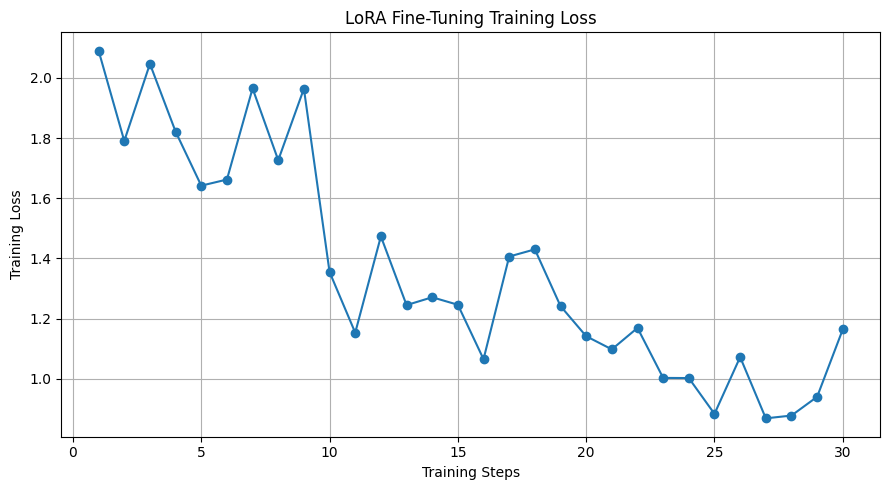

Loss graph saved: /content/Lab4_Results/training_loss.png


In [16]:
loss_records = [
    item for item in trainer.state.log_history
    if "loss" in item and "step" in item
]
if loss_records:
    steps = [x["step"] for x in loss_records]
    losses = [x["loss"] for x in loss_records]
    plt.figure(figsize=(9, 5))
    plt.plot(steps, losses, marker="o")
    plt.title("LoRA Fine-Tuning Training Loss")
    plt.xlabel("Training Steps")
    plt.ylabel("Training Loss")
    plt.grid(True)
    plt.tight_layout()
    loss_path = os.path.join(RESULT_DIR, "training_loss.png")
    plt.savefig(loss_path, dpi=250)
    plt.show()
    print("Loss graph saved:", loss_path)
else:
    print("No loss records were produced.")

## Step 17 – Export the results to Excel

In [17]:
excel_path = os.path.join(RESULT_DIR, "Lab4_Complete_Results.xlsx")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    pd.DataFrame(training_data).to_excel(writer, sheet_name="Training Dataset", index=False)
    baseline_df.to_excel(writer, sheet_name="Base Model", index=False)
    fine_tuned_df.to_excel(writer, sheet_name="Fine Tuned Model", index=False)
    comparison_df.to_excel(writer, sheet_name="Model Comparison", index=False)
    pd.DataFrame(trainer.state.log_history).to_excel(writer, sheet_name="Training Logs", index=False)

print("Excel file saved:", excel_path)

Excel file saved: /content/Lab4_Results/Lab4_Complete_Results.xlsx


## Step 18 – Package the outputs and adapter

The ZIP archive contains the CSV/Excel results, loss graph (if generated), and the LoRA adapter files.

In [18]:
ZIP_PATH = os.path.join(BASE_DIR, "Lab4_Complete_Outputs.zip")
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for folder, arcname in [(RESULT_DIR, "results"), (ADAPTER_DIR, "saved-model")]:
        for root, _, filenames in os.walk(folder):
            for filename in filenames:
                full_path = os.path.join(root, filename)
                relative = os.path.relpath(full_path, folder)
                archive.write(full_path, os.path.join(arcname, relative))

print("ZIP archive created:", ZIP_PATH)
print(f"ZIP size: {os.path.getsize(ZIP_PATH) / 1024**2:.2f} MB")

ZIP archive created: /content/Lab4_Complete_Outputs.zip
ZIP size: 17.72 MB


## Step 19 – Download the output ZIP (Google Colab)

Run this cell only in Google Colab. If running locally, use the printed `ZIP_PATH` to locate the archive.

In [19]:
try:
    from google.colab import files
    files.download(ZIP_PATH)
except ImportError:
    print("Not running in Google Colab. ZIP file is available at:", ZIP_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Observations and learning outcomes

After running the notebook, record:
- GPU name and memory (or state that CPU was used).
- Training loss and training time.
- Differences observed between the base and fine-tuned answers.
- Whether the fine-tuned model stayed focused on the computer-shop domain.
- Limitations: the dataset and unseen test set are small, so the results are a practical demonstration rather than a general benchmark.

## Conclusion

This practical demonstrates supervised fine-tuning of an instruction-tuned language model using PEFT LoRA. The base and fine-tuned models are evaluated with the same unseen questions, and the outputs, training logs, graph and adapter are saved for the digital portfolio.